In [1]:
from __future__ import annotations
 
import numpy as np
import numpy.fft as fft
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
 
from gear_signal import (
    EpicyclicGearParams,
    FaultParams,
    GearParams,
    GearSignalGenerator,
    HarmonicParams,
    ModulationParams,
    SignalConfig,
)

In [2]:
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]
STYLE  = "seaborn-v0_8-whitegrid"
 
plt.rcParams.update({
    "font.family":      "DejaVu Sans",
    "font.size":        11,
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "legend.fontsize":  10,
    "lines.linewidth":  1.6,
    "axes.spines.top":   False,
    "axes.spines.right": False,
})
 
FS       = 2_000
DURATION = 1.0
SEED     = 42

In [3]:
def plot_signal(t, x, title="Signal", color="#4C72B0"):
    """Two-panel plot: time domain (top) + RDFT magnitude (bottom)."""
    freqs = np.fft.rfftfreq(len(x), d=1.0 / FS)
    X_mag = np.abs(fft.rfft(x))
 
    with plt.style.context(STYLE):
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5))
 
        ax1.plot(t, x, color=color, lw=1.4, alpha=0.9)
        ax1.set_xlabel("Time (s)")
        ax1.set_ylabel("Amplitude")
        ax1.set_title(f"{title} — time domain")
        ax1.margins(x=0.01)
 
        ax2.plot(freqs, X_mag, color=color, lw=1.4, alpha=0.9)
        ax2.set_xlabel("Frequency (Hz)")
        ax2.set_ylabel("|X(f)|")
        ax2.set_title(f"{title} — RDFT magnitude")
        ax2.set_xlim(0, FS / 2)
        ax2.margins(x=0.01)
 
        fig.suptitle(title, fontsize=13, y=1.01)
        fig.tight_layout()
        plt.show()

/gpfs/data/ssa/users/d634375/FourierDiffusionConvolutiveSourceSeparation/data/gear_signal.py:369: UserWarning: Highest harmonic 1166.7 Hz ≥ Nyquist 1000.0 Hz. Increase sampling_rate or reduce M.
  warnings.warn(


Type A  |  shaft=11.67 Hz  mesh=116.67 Hz  samples=2000


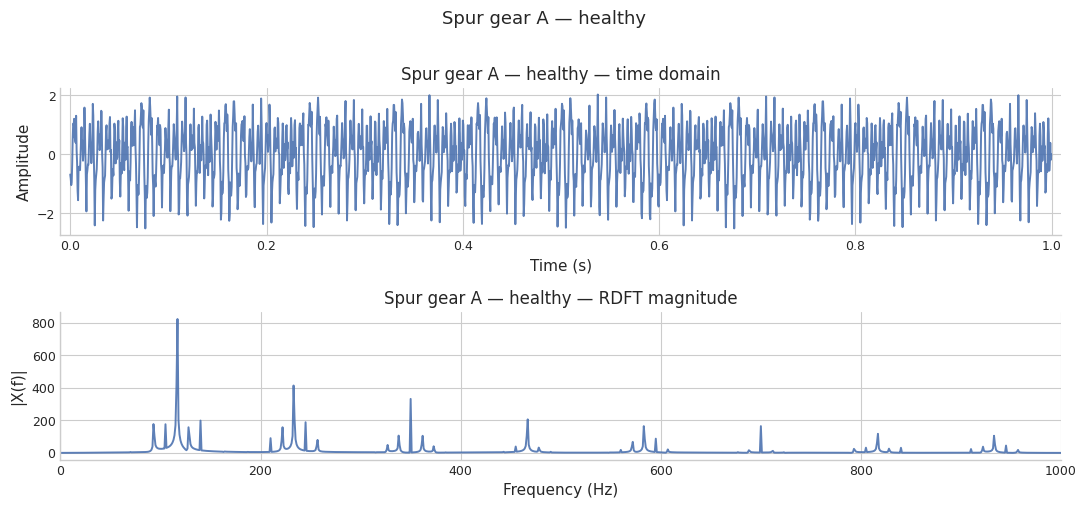

In [4]:
cfg_A = SignalConfig(
    duration=DURATION,
    sampling_rate=FS,
    gear=GearParams(teeth=10, speed_rpm=700),
    harmonic=HarmonicParams(M=10),
    modulation=ModulationParams(K=2
                            , alpha_scale=1),
    fault=FaultParams(enabled=False),
    noise_std=0,
    seed=None,
)
 
result_A = GearSignalGenerator(cfg_A).generate()
t_A, x_A = result_A["t"], result_A["signal"]
 
print(f"Type A  |  shaft={cfg_A.gear.shaft_freq:.2f} Hz  "
      f"mesh={cfg_A.gear.mesh_freq:.2f} Hz  "
      f"samples={len(x_A)}")
 
plot_signal(t_A, x_A, title="Spur gear A — healthy", color=COLORS[0])

In [6]:
def make_epi_cfg(carrier_rpm, Z_s, Z_p, Z_r, N_p=3, M=3, K=3, seed=SEED):
    return SignalConfig(
        duration=DURATION,
        sampling_rate=FS,
        gear=EpicyclicGearParams(
            speed_rpm=carrier_rpm,
            teeth=Z_s,
            N_p=N_p,
            Z_s=Z_s,
            Z_p=Z_p,
            Z_r=Z_r,
        ),
        harmonic=HarmonicParams(M=M),
        modulation=ModulationParams(K=K),
        fault=FaultParams(enabled=False),
        noise_std=0.0,
        seed=seed,
    )
 
def generate(cfg):
    res  = GearSignalGenerator(cfg).generate()
    return res["t"], res["signal"], res["metadata"]

In [7]:
cfg_ref = make_epi_cfg(carrier_rpm=100, Z_s=20, Z_p=30, Z_r=80, N_p=3)
_, _, meta = generate(cfg_ref)
 
print("=== Epicyclic frequency audit (carrier=100 RPM, Z_s=20, Z_p=30, Z_r=80) ===")
print(f"  carrier_freq      : {meta['carrier_freq_hz']:.4f} Hz")
print(f"  sun_freq          : {meta['sun_freq_hz']:.4f} Hz   [f_c*(Z_r+Z_s)/Z_s]")
print(f"  planet_spin_freq  : {meta['planet_spin_freq_hz']:.4f} Hz   [f_c*Z_r/(2*Z_p)]")
print(f"  mesh_freq_ring    : {meta['mesh_freq_ring_hz']:.4f} Hz   [f_c*Z_r]")
print(f"  mesh_freq_sun     : {meta['mesh_freq_sun_hz']:.4f} Hz   [f_c*(Z_r+Z_s)]")
print(f"  Nyquist           : {FS/2} Hz")
print()
for label, fm in [("ring", meta['mesh_freq_ring_hz']), ("sun", meta['mesh_freq_sun_hz'])]:
    for m in range(1, meta['M']+1):
        fh   = m * fm
        flag = "❌ ABOVE NYQUIST" if fh >= FS/2 else "✓"
        print(f"  m={m}  {label} harmonic: {fh:.2f} Hz  {flag}")

=== Epicyclic frequency audit (carrier=100 RPM, Z_s=20, Z_p=30, Z_r=80) ===
  carrier_freq      : 1.6667 Hz
  sun_freq          : 8.3333 Hz   [f_c*(Z_r+Z_s)/Z_s]
  planet_spin_freq  : 2.2222 Hz   [f_c*Z_r/(2*Z_p)]
  mesh_freq_ring    : 133.3333 Hz   [f_c*Z_r]
  mesh_freq_sun     : 166.6667 Hz   [f_c*(Z_r+Z_s)]
  Nyquist           : 1000.0 Hz

  m=1  ring harmonic: 133.33 Hz  ✓
  m=2  ring harmonic: 266.67 Hz  ✓
  m=3  ring harmonic: 400.00 Hz  ✓
  m=1  sun harmonic: 166.67 Hz  ✓
  m=2  sun harmonic: 333.33 Hz  ✓
  m=3  sun harmonic: 500.00 Hz  ✓


Z_s=18  f_mesh_sun=163.33 Hz  rms=1.07236
Z_s=20  f_mesh_sun=166.67 Hz  rms=1.08478
Z_s=24  f_mesh_sun=173.33 Hz  rms=1.07282


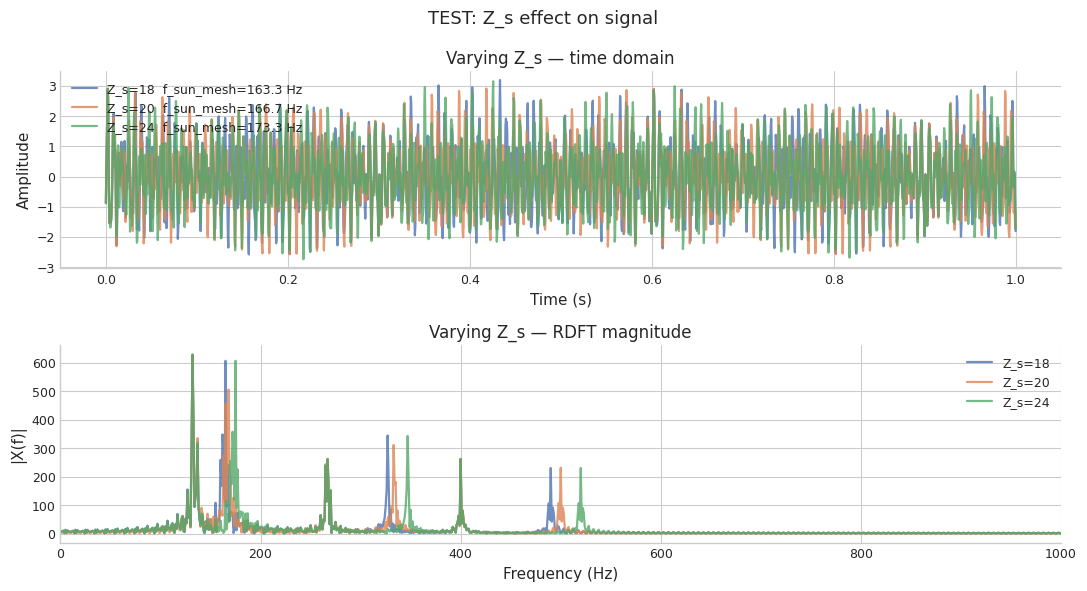

In [8]:
t_ref = np.linspace(0, DURATION, FS, endpoint=False)
freqs = np.fft.rfftfreq(FS, d=1.0/FS)
 
Z_s_values = [18, 20, 24]
signals_Zs = []
 
for Z_s in Z_s_values:
    cfg = make_epi_cfg(carrier_rpm=100, Z_s=Z_s, Z_p=30, Z_r=80)
    t, x, meta = generate(cfg)
    signals_Zs.append((Z_s, x, meta))
    print(f"Z_s={Z_s}  f_mesh_sun={meta['mesh_freq_sun_hz']:.2f} Hz  "
          f"rms={np.sqrt(np.mean(x**2)):.5f}")
 
with plt.style.context(STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=False)
 
    for idx, (Z_s, x, meta) in enumerate(signals_Zs):
        axes[0].plot(t_ref, x, color=COLORS[idx], alpha=0.8,
                     label=f"Z_s={Z_s}  f_sun_mesh={meta['mesh_freq_sun_hz']:.1f} Hz")
        axes[1].plot(freqs, np.abs(fft.rfft(x)), color=COLORS[idx], alpha=0.8,
                     label=f"Z_s={Z_s}")
 
    axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Varying Z_s — time domain"); axes[0].legend(fontsize=9)
    axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("|X(f)|")
    axes[1].set_title("Varying Z_s — RDFT magnitude"); axes[1].set_xlim(0, FS/2)
    axes[1].legend(fontsize=9)
    fig.suptitle("TEST: Z_s effect on signal", fontsize=13)
    fig.tight_layout(); plt.show()

Z_r=60  f_mesh_ring=100.00 Hz  f_mesh_sun=133.33 Hz  rms=1.08372
Z_r=70  f_mesh_ring=116.67 Hz  f_mesh_sun=150.00 Hz  rms=1.08490
Z_r=80  f_mesh_ring=133.33 Hz  f_mesh_sun=166.67 Hz  rms=1.08478


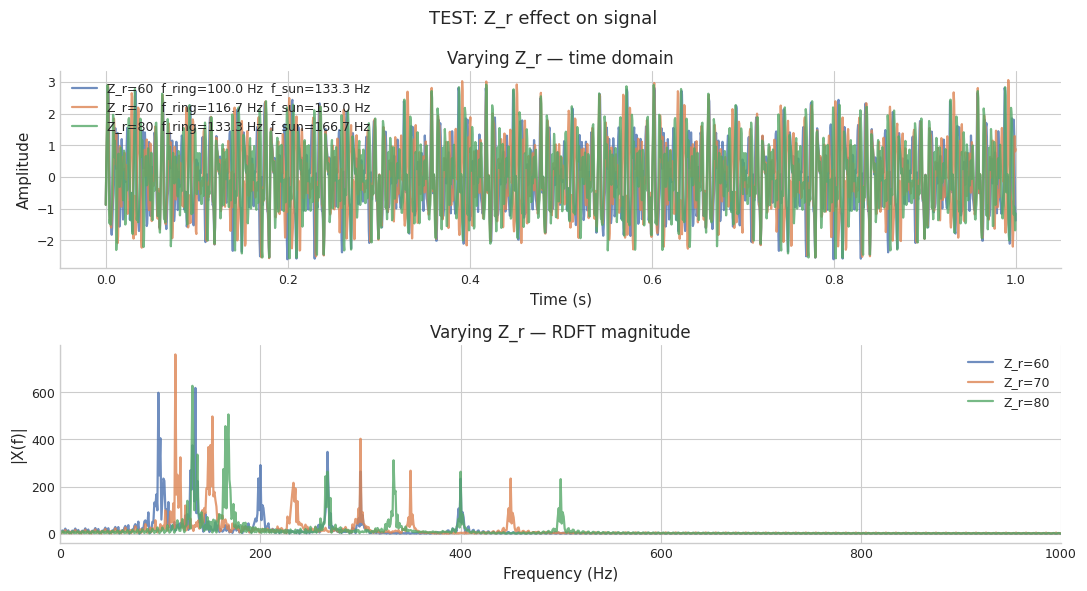

In [9]:
Z_r_values = [60, 70, 80]
signals_Zr = []
 
for Z_r in Z_r_values:
    cfg = make_epi_cfg(carrier_rpm=100, Z_s=20, Z_p=30, Z_r=Z_r)
    t, x, meta = generate(cfg)
    signals_Zr.append((Z_r, x, meta))
    print(f"Z_r={Z_r}  f_mesh_ring={meta['mesh_freq_ring_hz']:.2f} Hz  "
          f"f_mesh_sun={meta['mesh_freq_sun_hz']:.2f} Hz  "
          f"rms={np.sqrt(np.mean(x**2)):.5f}")
 
with plt.style.context(STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
 
    for idx, (Z_r, x, meta) in enumerate(signals_Zr):
        axes[0].plot(t_ref, x, color=COLORS[idx], alpha=0.8,
                     label=f"Z_r={Z_r}  f_ring={meta['mesh_freq_ring_hz']:.1f} Hz  "
                           f"f_sun={meta['mesh_freq_sun_hz']:.1f} Hz")
        axes[1].plot(freqs, np.abs(fft.rfft(x)), color=COLORS[idx], alpha=0.8,
                     label=f"Z_r={Z_r}")
 
    axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Varying Z_r — time domain"); axes[0].legend(fontsize=9)
    axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("|X(f)|")
    axes[1].set_title("Varying Z_r — RDFT magnitude"); axes[1].set_xlim(0, FS/2)
    axes[1].legend(fontsize=9)
    fig.suptitle("TEST: Z_r effect on signal", fontsize=13)
    fig.tight_layout(); plt.show()

N_p=2  rms=0.99036
N_p=3  rms=1.08478
N_p=4  rms=1.11453


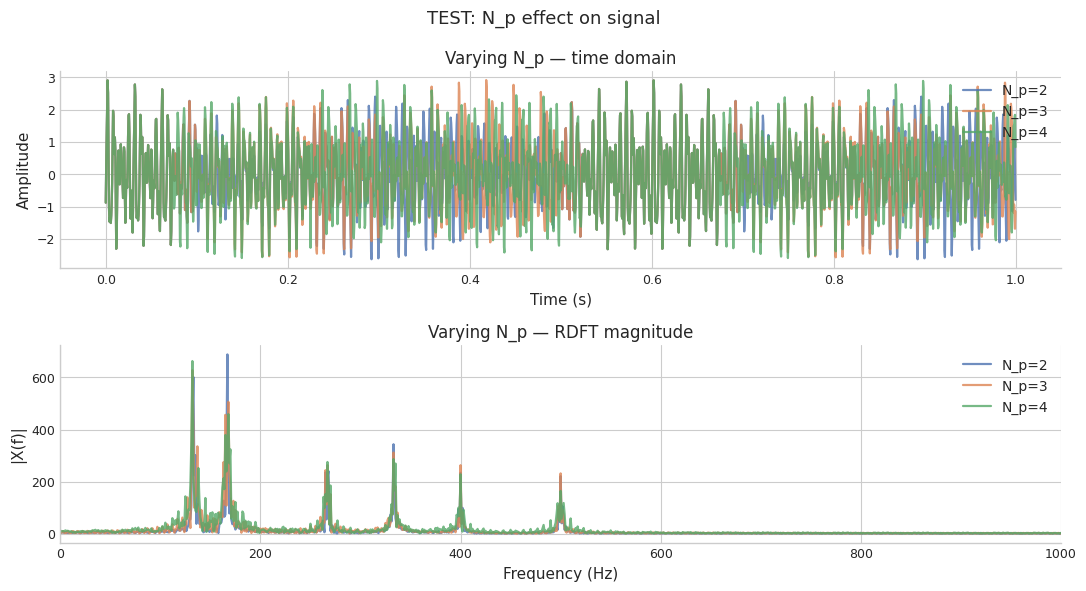

In [10]:
N_p_values = [2, 3, 4]
signals_Np = []
 
for N_p in N_p_values:
    cfg = make_epi_cfg(carrier_rpm=100, Z_s=20, Z_p=30, Z_r=80, N_p=N_p)
    t, x, meta = generate(cfg)
    signals_Np.append((N_p, x))
    print(f"N_p={N_p}  rms={np.sqrt(np.mean(x**2)):.5f}")
 
with plt.style.context(STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
 
    for idx, (N_p, x) in enumerate(signals_Np):
        axes[0].plot(t_ref, x, color=COLORS[idx], alpha=0.8, label=f"N_p={N_p}")
        axes[1].plot(freqs, np.abs(fft.rfft(x)), color=COLORS[idx], alpha=0.8,
                     label=f"N_p={N_p}")
 
    axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Varying N_p — time domain"); axes[0].legend()
    axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("|X(f)|")
    axes[1].set_title("Varying N_p — RDFT magnitude"); axes[1].set_xlim(0, FS/2)
    axes[1].legend()
    fig.suptitle("TEST: N_p effect on signal", fontsize=13)
    fig.tight_layout(); plt.show()

Z_p=25  planet_spin=2.667 Hz  rms=1.08478  (healthy signal: no effect expected — Z_p only sets fault period)
Z_p=30  planet_spin=2.222 Hz  rms=1.08478  (healthy signal: no effect expected — Z_p only sets fault period)
Z_p=35  planet_spin=1.905 Hz  rms=1.08478  (healthy signal: no effect expected — Z_p only sets fault period)


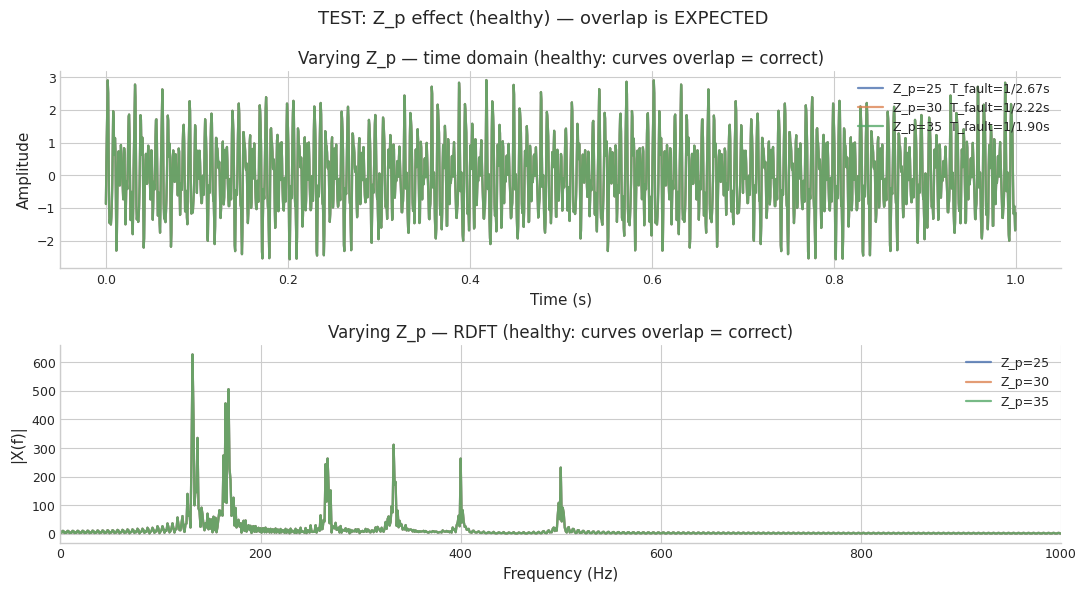

In [11]:
Z_p_values = [25, 30, 35]
signals_Zp = []
 
for Z_p in Z_p_values:
    cfg = make_epi_cfg(carrier_rpm=100, Z_s=20, Z_p=Z_p, Z_r=80)
    t, x, meta = generate(cfg)
    signals_Zp.append((Z_p, x, meta))
    print(f"Z_p={Z_p}  planet_spin={meta['planet_spin_freq_hz']:.3f} Hz  "
          f"rms={np.sqrt(np.mean(x**2)):.5f}  "
          f"(healthy signal: no effect expected — Z_p only sets fault period)")
 
with plt.style.context(STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
 
    for idx, (Z_p, x, meta) in enumerate(signals_Zp):
        axes[0].plot(t_ref, x, color=COLORS[idx], alpha=0.8,
                     label=f"Z_p={Z_p}  T_fault=1/{meta['planet_spin_freq_hz']:.2f}s")
        axes[1].plot(freqs, np.abs(fft.rfft(x)), color=COLORS[idx], alpha=0.8,
                     label=f"Z_p={Z_p}")
 
    axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Amplitude")
    axes[0].set_title("Varying Z_p — time domain (healthy: curves overlap = correct)")
    axes[0].legend(fontsize=9)
    axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("|X(f)|")
    axes[1].set_title("Varying Z_p — RDFT (healthy: curves overlap = correct)")
    axes[1].set_xlim(0, FS/2); axes[1].legend(fontsize=9)
    fig.suptitle("TEST: Z_p effect (healthy) — overlap is EXPECTED", fontsize=13)
    fig.tight_layout(); plt.show()

Z_p=25  planet_spin=2.667 Hz  →  fault impulse every 0.375 s
Z_p=30  planet_spin=2.222 Hz  →  fault impulse every 0.450 s
Z_p=35  planet_spin=1.905 Hz  →  fault impulse every 0.525 s


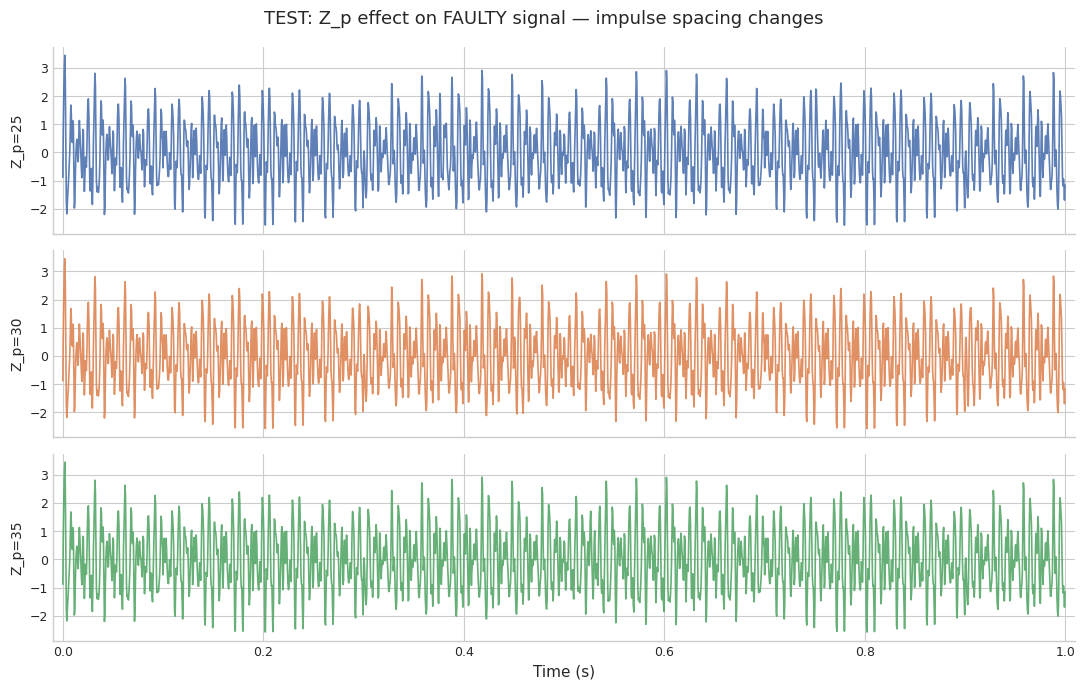

In [12]:
signals_Zp_fault = []
 
for Z_p in Z_p_values:
    cfg = make_epi_cfg(carrier_rpm=100, Z_s=20, Z_p=Z_p, Z_r=80)
    cfg.fault = FaultParams(
        enabled=True,
        impulse_amplitude=1.0,
        resonance_freq=200.0,
        damping_ratio=0.08,
    )
    t, x, meta = generate(cfg)
    signals_Zp_fault.append((Z_p, x, meta))
    print(f"Z_p={Z_p}  planet_spin={meta['planet_spin_freq_hz']:.3f} Hz  "
          f"→  fault impulse every {1/meta['planet_spin_freq_hz']:.3f} s")
 
with plt.style.context(STYLE):
    fig, axes = plt.subplots(len(Z_p_values), 1, figsize=(11, 7), sharex=True)
 
    for ax, (Z_p, x, meta) in zip(axes, signals_Zp_fault):
        ax.plot(t_ref, x, color=COLORS[Z_p_values.index(Z_p)], lw=1.2, alpha=0.9)
        ax.set_ylabel(f"Z_p={Z_p}", fontsize=10)
        ax.margins(x=0.01)
 
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle("TEST: Z_p effect on FAULTY signal — impulse spacing changes", fontsize=13)
    fig.tight_layout(); plt.show()
 

/gpfs/data/ssa/users/d634375/FourierDiffusionConvolutiveSourceSeparation/data/gear_signal.py:361: UserWarning: Epicyclic sun–planet mesh: highest harmonic 1000.0 Hz ≥ Nyquist 1000.0 Hz. Increase sampling_rate or reduce M / carrier_rpm.
  warnings.warn(


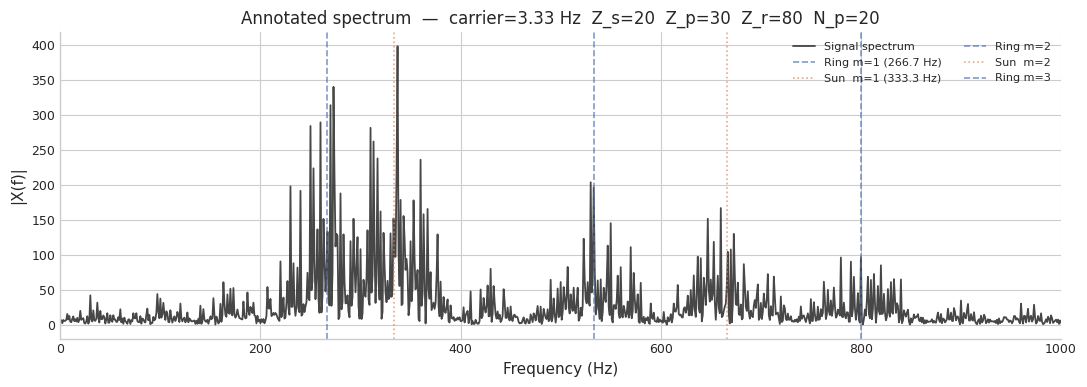

In [16]:
cfg_ref = make_epi_cfg(carrier_rpm=200, Z_s=20, Z_p=30, Z_r=80, N_p=20, M=3)
t, x, meta = generate(cfg_ref)
 
f_ring = meta['mesh_freq_ring_hz']
f_sun  = meta['mesh_freq_sun_hz']
X_mag  = np.abs(fft.rfft(x))
 
with plt.style.context(STYLE):
    fig, ax = plt.subplots(figsize=(11, 4))
 
    ax.plot(freqs, X_mag, color="#333333", lw=1.3, alpha=0.9, label="Signal spectrum")
 
    for m in range(1, meta['M']+1):
        fh_r = m * f_ring
        fh_s = m * f_sun
        if fh_r < FS/2:
            ax.axvline(fh_r, color=COLORS[0], lw=1.2, ls="--", alpha=0.7,
                       label=f"Ring m={m} ({fh_r:.1f} Hz)" if m == 1 else f"Ring m={m}")
        if fh_s < FS/2:
            ax.axvline(fh_s, color=COLORS[1], lw=1.2, ls=":",  alpha=0.7,
                       label=f"Sun  m={m} ({fh_s:.1f} Hz)" if m == 1 else f"Sun  m={m}")
 
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("|X(f)|")
    ax.set_xlim(0, FS/2)
    ax.set_title(
        f"Annotated spectrum  —  "
        f"carrier={meta['carrier_freq_hz']:.2f} Hz  "
        f"Z_s={meta['Z_s']}  Z_p={meta['Z_p']}  Z_r={meta['Z_r']}  N_p={meta['N_p']}"
    )
    ax.legend(fontsize=8, ncol=2, framealpha=0.7)
    fig.tight_layout(); plt.show()